# 1. Laden der Librarys welche man braucht um dieses Notebook durchlaufen zu lassen

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import functions

import app

import warnings
warnings.filterwarnings("ignore")

from IPython.display import display


%load_ext autoreload
%autoreload 2

# 2. Laden der Daten (Manuell)

In der Applikation wie sie im Presswerk integriert ist werden die Daten jedoch automatisch geladen

In [2]:
#DataFrame mit allen Produktionsdaten
df = pd.read_csv("Prod_data/data.csv", sep=',')

# # Einstellen des Predictions Horizont welchen man wählen will
# start = '2022-10-15 '
# end = '2023-03-21 17:29:27'

# df["time"] = pd.to_datetime(df["time"])
# df = df.loc[(df["time"] > start) & (df["time"] < end)]

In [3]:
#Wenn man ein beliebiges Dataset laden will (nicht unbedingt Motorströme) dann kann man auch nur das Dataframe laden.
df = df[['time', 'Spannung_L1_L2_Hauptantrieb', 'Spannung_L2_L3_Hauptantrieb', 'Spannung_L3_L1_Hauptantrieb','Strom_L1_Hauptantrieb','Strom_L2_Hauptantrieb', 'Strom_L3_Hauptantrieb']]

# 3. Trainingsinstanz erzeugen 

Hier wird diese Instanz "session" genannt, aber man könnte sie beliebig benennen

In [4]:
session = app.Inference(df)

Raw Data imported


# 4. Preprocessing 

In [5]:
print("Execution times:")
preprocessed_data = session.preprocessing(feature_selection=True)

Execution times:
Spannung_L1_L2_abweichung_mittlere_Leitungsspannung
Spannung_L2_L3_abweichung_mittlere_Leitungsspannung
Spannung_L3_L1_abweichung_mittlere_Leitungsspannung
Strom_L1_abweichung_mittlerer_Leitungsstrom
Strom_L2_abweichung_mittlerer_Leitungsstrom
Strom_L3_abweichung_mittlerer_Leitungsstrom


# 5. Prediction 

Hier kann man sich für die verschiedenen Zeiträume einen aussuchen und das Modell laufen lassen auf die Daten (Durch auskommentieren kann man mal ausprobieren)

In [6]:
print("Execution times:")
results = session.predictAnomalyScores(path = 'models/', model_name = 'model_LSTM_AE_embedding_8_epochs_10_sequence_length_3_unsupervised_20231009feature_selection_True/', sequence_length=3)

Execution times:


2023-10-09 14:48:45.624433: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


7722/7722 [==============================] - 22s 3ms/step
45.374326944351196


# 6. Define Threshold

Man legt die threshold so fest, dass es im Trainingsset ungefähr eine conta von 1% gibt

In [23]:
threshold_ = 0.42

In [24]:
session.assignHealthStatus(threshold=threshold_)

In [25]:
len(session.results[:'2023-03-01'])

99683

In [26]:
len(session.results[:'2023-03-01'].loc[session.results["Label_LSTM_AE"] == 1])

1051

In [27]:
len(session.results[:'2023-03-01'].loc[session.results["Label_LSTM_AE"] == 1])/len(session.results[:'2023-03-01'])

0.010543422649799865

# 7. Get Anomaly reasons

Es werden die Features rausgezogen welche einen hohen reconstruction error haben und diese werden als Grund dafür genommen das eine Anomalie aufgetreten ist. 

In [28]:
explained_anomalys = session.explain_anomalys()

7722/7722 [==============================] - 21s 3ms/step


In [29]:
explained_anomalys

,Loss_mse,Label_LSTM_AE,reason 1,reason 2,reason 3,störung,Normalized_Loss_mse
time,,,,,,,
2022-10-21 17:26:00+00:00,0.610407,1,Strom_L3_abweichung_mittlerer_Leitungsstrom_std,Strom_L2_abweichung_mittlerer_Leitungsstrom_std,Spannung_L1_L2_abweichung_mittlere_Leitungsspa...,0.0,0.120814
2022-10-21 17:28:00+00:00,0.656531,1,Strom_L3_abweichung_mittlerer_Leitungsstrom_std,Strom_L2_abweichung_mittlerer_Leitungsstrom_std,Spannung_L1_L2_abweichung_mittlere_Leitungsspa...,0.0,0.129982
2022-10-21 17:30:00+00:00,0.560236,1,Strom_L2_abweichung_mittlerer_Leitungsstrom_std,Strom_L3_abweichung_mittlerer_Leitungsstrom_std,Spannung_L1_L2_abweichung_mittlere_Leitungsspa...,1.0,0.110842
2022-10-21 17:32:00+00:00,0.434496,1,Strom_L2_abweichung_mittlerer_Leitungsstrom_std,Strom_L3_abweichung_mittlerer_Leitungsstrom_std,Spannung_L1_L2_abweichung_mittlere_Leitungsspa...,1.0,0.085849
2022-10-21 17:36:00+00:00,0.440657,1,Strom_L2_abweichung_mittlerer_Leitungsstrom_std,Strom_L3_abweichung_mittlerer_Leitungsstrom_std,Strom_L2_abweichung_mittlerer_Leitungsstrom_mean,1.0,0.087073
...,...,...,...,...,...,...,...
2023-09-09 16:18:00+00:00,1.032922,1,Spannung_L1_L2_abweichung_mittlere_Leitungsspa...,Strom_L1_abweichung_mittlerer_Leitungsstrom_std,Strom_L3_abweichung_mittlerer_Leitungsstrom_std,0.0,0.204795
2023-09-09 16:20:00+00:00,0.940493,1,Strom_L1_abweichung_mittlerer_Leitungsstrom_std,Spannung_L1_L2_abweichung_mittlere_Leitungsspa...,Strom_L3_abweichung_mittlerer_Leitungsstrom_std,0.0,0.186424
2023-09-09 16:22:00+00:00,0.831407,1,Strom_L1_abweichung_mittlerer_Leitungsstrom_std,Spannung_L1_L2_abweichung_mittlere_Leitungsspa...,Spannung_L3_L1_abweichung_mittlere_Leitungsspa...,0.0,0.164741


# Extra: Evaluation

Es wird in der Applikation nur bis hier integriert, der Rest ab hier dient nur zur Evaluation des Modells im Bezug auf die historischen Daten

In [30]:
session.loadValidationData()

In [31]:
validation_df = pd.read_csv("Störungen_data/validation_df")

validation_df["time"] = pd.to_datetime(validation_df["time"])

In [32]:
# #Lokal
# for index, row in validation_df.iterrows():
    
#     print(row["time"])
#     print(row["APLSTATTXT"])
    
#     session.results.Loss_mse.plot(color = 'blue')
    
#     plt.scatter(session.results.Loss_mse.loc[session.results.Loss_mse > threshold_].index, session.results.Loss_mse.loc[session.results.Loss_mse > threshold_], label = 'Anomalien', color = 'red')
    
#     start = row["time"] - pd.Timedelta(hours=4)
#     end = row["time"] + pd.Timedelta(hours=4)
    
#     plt.axvline(pd.to_datetime(row["time"]), color = "black", linewidth = 2, alpha = 0.1)
    
#     plt.xlim([start, end])
    
#     plt.show()
    
#     session.df_raw[(session.df_raw.index > str(start)) & (session.df_raw.index < str(end))].Strom_L1_Hauptantrieb.plot()
#     session.df_raw[(session.df_raw.index > str(start)) & (session.df_raw.index < str(end))].Strom_L2_Hauptantrieb.plot()
#     session.df_raw[(session.df_raw.index > str(start)) & (session.df_raw.index < str(end))].Strom_L3_Hauptantrieb.plot()
    
#     plt.title("Stromdaten")
    
#     plt.xlim([start, end])
    
#     plt.show()
    
#     session.df_raw[(session.df_raw.index > str(start)) & (session.df_raw.index < str(end))].Spannung_L1_L2_Hauptantrieb.plot()
#     session.df_raw[(session.df_raw.index > str(start)) & (session.df_raw.index < str(end))].Spannung_L2_L3_Hauptantrieb.plot()
#     session.df_raw[(session.df_raw.index > str(start)) & (session.df_raw.index < str(end))].Spannung_L3_L1_Hauptantrieb.plot()
    
#     plt.title("Spannungsdaten")
    
#     plt.xlim([start, end])
    
#     plt.show()
    
#     print("Anomaly Reason:")
#     display(explained_anomalys[(explained_anomalys.index > str(start)) & (explained_anomalys.index < str(end))])

## Label / Validierungsdaten laden (Manuell)

<Axes: >

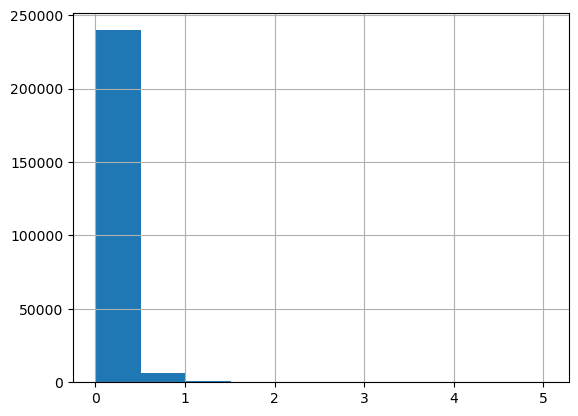

In [33]:
session.results.Loss_mse.hist()

F1-Score: 
0.5180687873405457
Confusion matrix: 
         Normal  Anomaly
Normal   224149      805
Anomaly   14118     8021


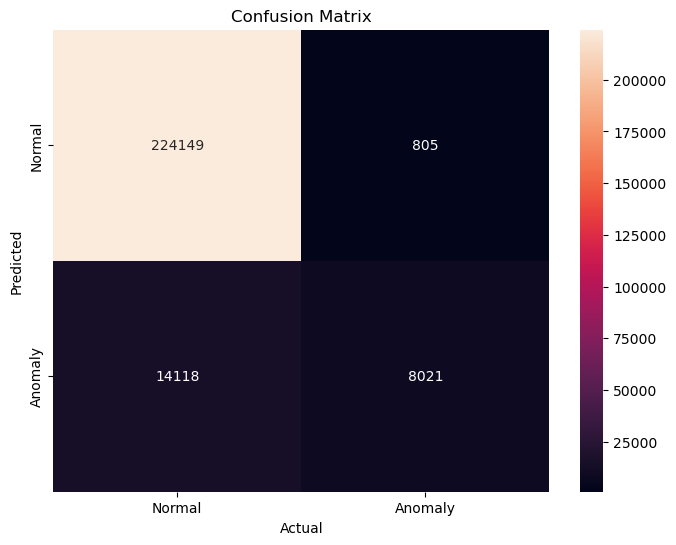

None
ROC-AUC: 


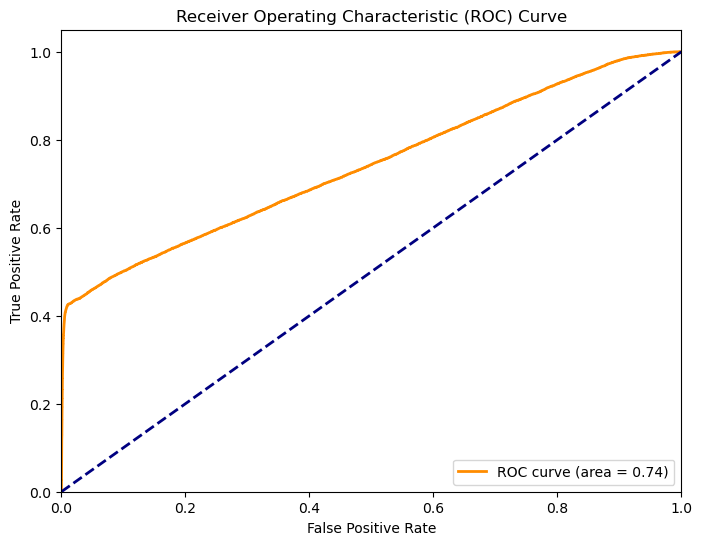

0.7406923120298352
Precision: 
0.9087922048493089
Recall: 
0.3623018203170875
Accuracy: 
0.9396057354923045
Precision-Recall-Curve: 


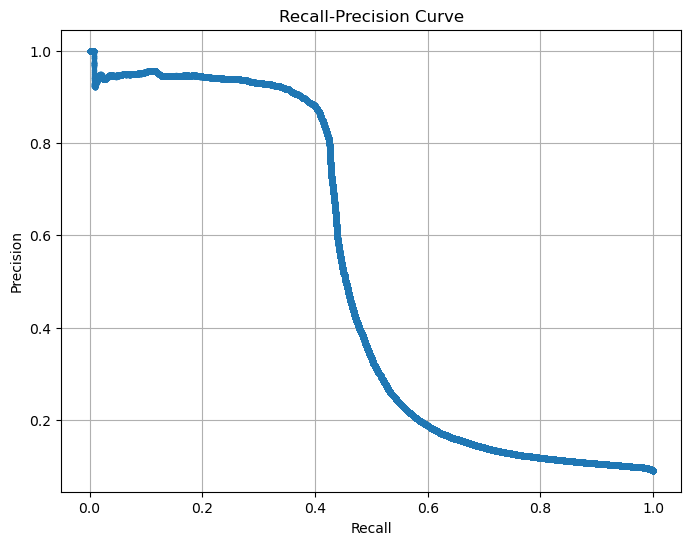

None


In [34]:
session.evaluate()

In [35]:
results.to_csv("results/results_LSTM_AE_raw")

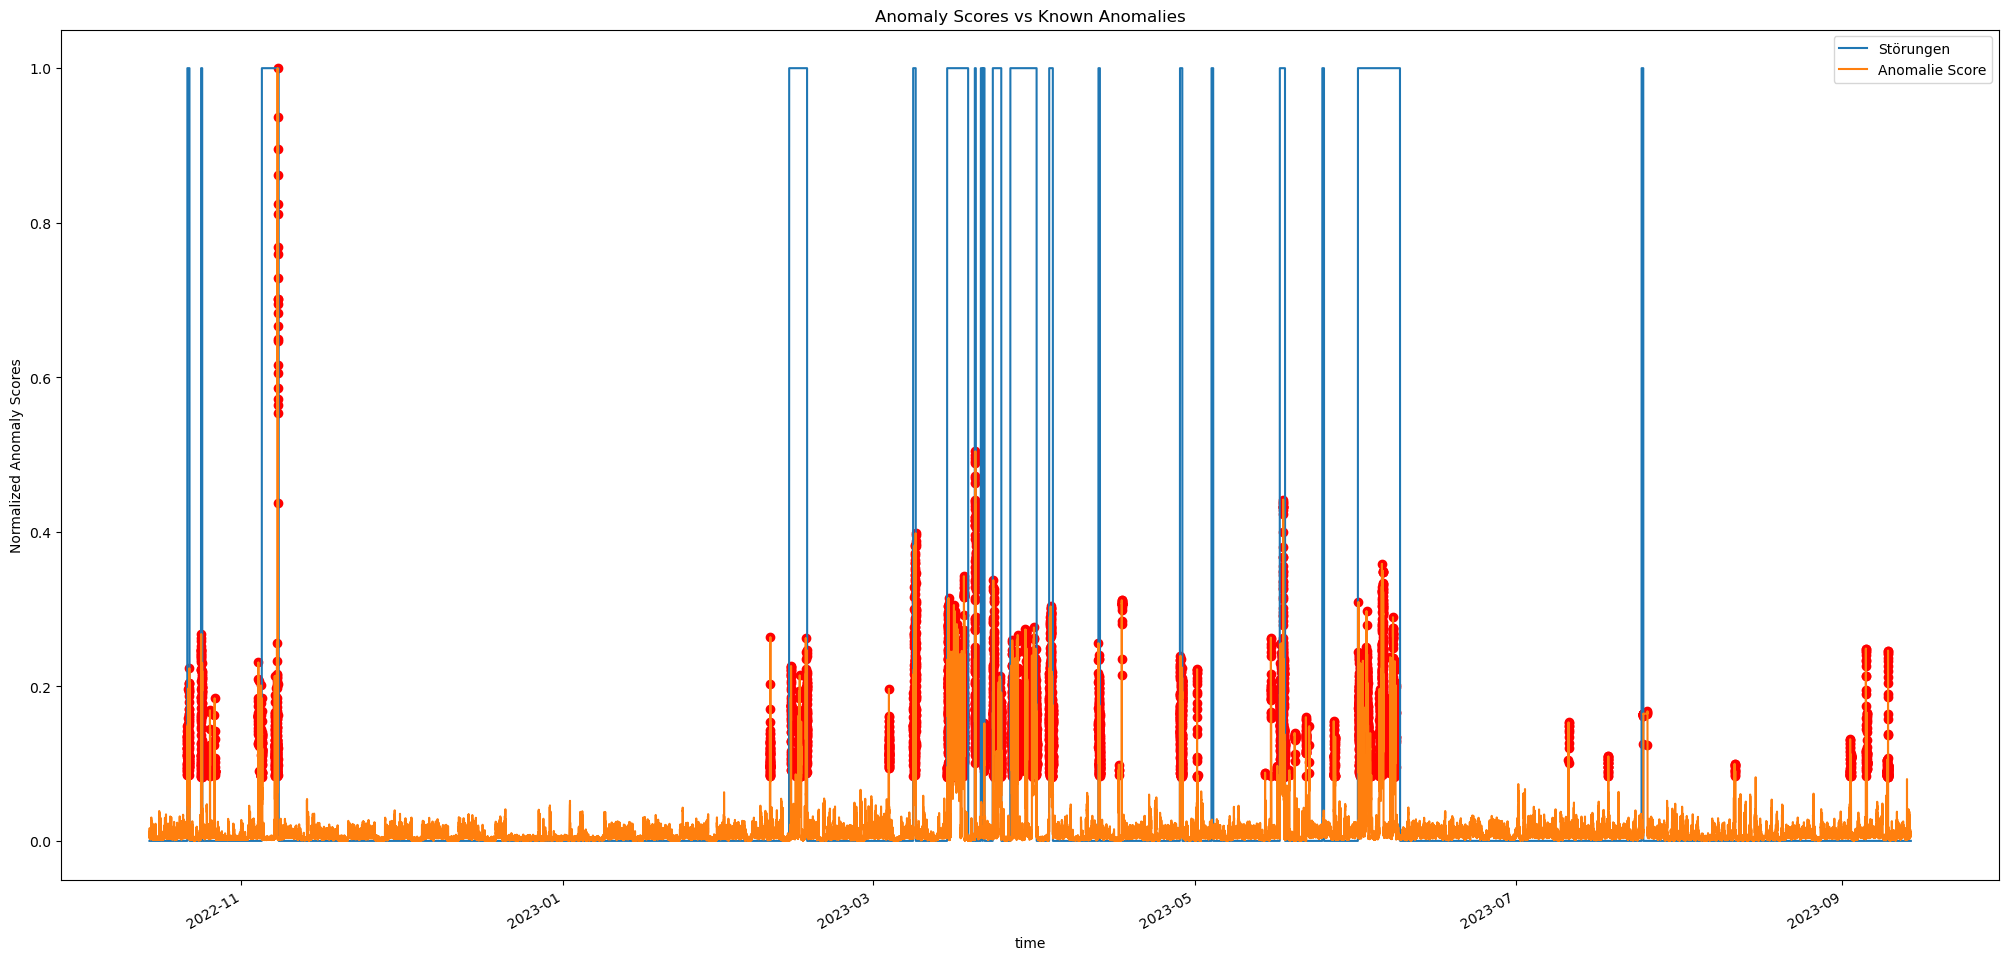

In [36]:
# Normalize the Loss_mse values
min_loss = results["Loss_mse"].min()
max_loss = results["Loss_mse"].max()
results["Normalized_Loss_mse"] = (results["Loss_mse"] - min_loss) / (max_loss - min_loss)

plt.figure(figsize=(25, 12.5))
anomalys = results.loc[results["Label_LSTM_AE"] == 1]
plt.scatter(anomalys.index, anomalys["Normalized_Loss_mse"], color="red")

plt.ylabel("Normalized Anomaly Scores")
plt.title("Anomaly Scores vs Known Anomalies")

results.störung.plot(label="Störungen")
results.Normalized_Loss_mse.plot(label="Anomalie Score")

plt.legend()
plt.savefig("results/AnomalyScoresvsKnownAnomalysLSTMAE")

In [37]:
import keras
from keras.models import load_model

embeddings = functions.get_embeddings(model = load_model("models/model_LSTM_AE_embedding_8_epochs_10_sequence_length_3_unsupervised_20231009feature_selection_True"), data = session.X,sequence_length = 3)

7722/7722 [==============================] - 15s 2ms/step


In [44]:
from sklearn.manifold import TSNE

# Create a t-SNE model with the desired number of dimensions (e.g., 2 for 2D visualization)
tsne = TSNE(n_components=2, random_state=42, n_iter = 400)

# Fit the t-SNE model to your embedding vectors
embedding_tsne = tsne.fit_transform(embeddings)

In [45]:
x = pd.DataFrame(embedding_tsne, index = session.results.index, columns= ["X", "Y"])

In [46]:
visu = pd.concat([session.results, x], axis = 1)

In [ ]:
# Create a scatter plot of the t-SNE result
plt.figure(figsize=(8, 6))
plt.scatter(visu.loc[visu["Label_LSTM_AE"] == 1]["X"], visu.loc[visu["Label_LSTM_AE"] == 1]["Y"], color = "red", alpha = 0.05, label = "Anomalous Windows")  # Adjust marker size as needed
plt.scatter(visu.loc[visu["Label_LSTM_AE"] == 0]["X"], visu.loc[visu["Label_LSTM_AE"] == 0]["Y"], color = "green", alpha = 0.01, label = "Normal Windows") 
plt.title('Highlight: High reconstruction error')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.show()

In [ ]:
red_dots = visu.loc[(visu["Label_LSTM_AE"] == 1)]

plt.scatter(red_dots.index, red_dots.Loss_mse, color = "red") 

visu.Loss_mse.plot(color = "blue", alpha = 0.1)

In [ ]:
# Create a scatter plot of the t-SNE result
plt.figure(figsize=(8, 6))
plt.scatter(visu.loc[visu["störung"] == 1]["X"], visu.loc[visu["störung"] == 1]["Y"], color = "red", alpha = 0.05, label = "Ground Truth Anomalys")  # Adjust marker size as needed
plt.scatter(visu.loc[visu["störung"] == 0]["X"], visu.loc[visu["störung"] == 0]["Y"], color = "green", alpha = 0.01, label = "Normal Windows") 
plt.title('Highlight: Groundtruth anomalys')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.show()